# Assignment 3, Part 1 — Data, MLPs, CNNs, and spatial structure

**Praveen, roll m26csa003. Split seed 26003.**

This notebook is the dataset check, Question 1, and Question 2. It loads the saved stratified split and the logs written by the training jobs. It does not draw a new split, and it does not read any variable from `Assignment_3_Part_2.ipynb`.

The model and training code that produced the logs is imported from `src/`. A second copy inside this notebook would be free to drift away from those logs, so the notebook calls that code rather than restating it. Set `RECOMPUTE = True` on a GPU node only if you intend to repeat training.

## 1. Objectives

**Question 1.** Test one reason an MLP is weak on CIFAR-10, and separate that reason from "not enough parameters" and "it overfits". Then watch a wide MLP train on partly randomised labels, and decide from the trajectory whether useful structure appears before memorisation.

**Question 2.** Use that same matched MLP and matched CNN. Destroy spatial neighbourhoods while keeping the pixel values, and, separately, remove colour while keeping the neighbourhoods. The same transform is applied to train, validation, and test. Report test accuracy and confidence.

## 2. Imports, paths, and the recompute switch

In [1]:
from pathlib import Path
import sys

HERE = Path.cwd().resolve()
CANDIDATES = [HERE, *HERE.parents, Path("/scratch/m26csa003/ML_assignment_3")]
ROOT = next(path for path in CANDIDATES if (path / "src" / "common" / "data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Saved logs are the reported results. Set this to True only on a GPU node
# when you intend to repeat training. The training entry points are the same
# functions the batch jobs called.
RECOMPUTE = False

import os
os.environ.setdefault("PYTHONNOUSERSITE", "1")

from IPython.display import display, Image, Markdown, HTML

def show_rows(rows, columns=None, digits=4):
    """Render a list of dicts as an HTML table."""
    if not rows:
        display(Markdown("*No rows.*"))
        return
    columns = list(columns or rows[0].keys())

    def cell(value):
        if isinstance(value, float):
            return f"{value:.{digits}f}"
        return "" if value is None else str(value)

    head = "".join(f"<th style='text-align:left;padding:4px 8px'>{name}</th>" for name in columns)
    body = []
    for row in rows:
        body.append("<tr>" + "".join(
            f"<td style='padding:4px 8px'>{cell(row.get(name, ''))}</td>" for name in columns
        ) + "</tr>")
    display(HTML(
        "<table style='border-collapse:collapse;font-size:13px'>"
        f"<thead><tr>{head}</tr></thead><tbody>{''.join(body)}</tbody></table>"
    ))

def show_figure(relative, width=720):
    path = ROOT / relative
    if not path.exists():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))

print("Project root:", ROOT)
print("RECOMPUTE =", RECOMPUTE)

Project root: /scratch/m26csa003/ML_assignment_3
RECOMPUTE = False


## 3. Dataset

Seed 26003 is the digits of roll m26csa003, in order. `prepare_dataset` reloads `splits/split_seed26003.npz` and checks that a fresh draw from that seed matches it. It refuses to replace the file. Channel mean and population standard deviation are computed from the 45,000 training images only.

Files already downloaded and verified


Files already downloaded and verified


split status: reloaded
train index sha256: 97af65b491226b292df93e2a67fa52812257f3db3c0f045799d4eb675c70f04a
validation index sha256: 51c33528721993c8a467510f7cb42cbc6a612d0a06d7677daa6feaadbf1df23c


train,validation,test,per class train,per class validation,overlap
45000,5000,10000,4500,500,0


train mean RGB: [0.491432, 0.482107, 0.446561]
train std RGB: [0.246945, 0.243417, 0.261535]


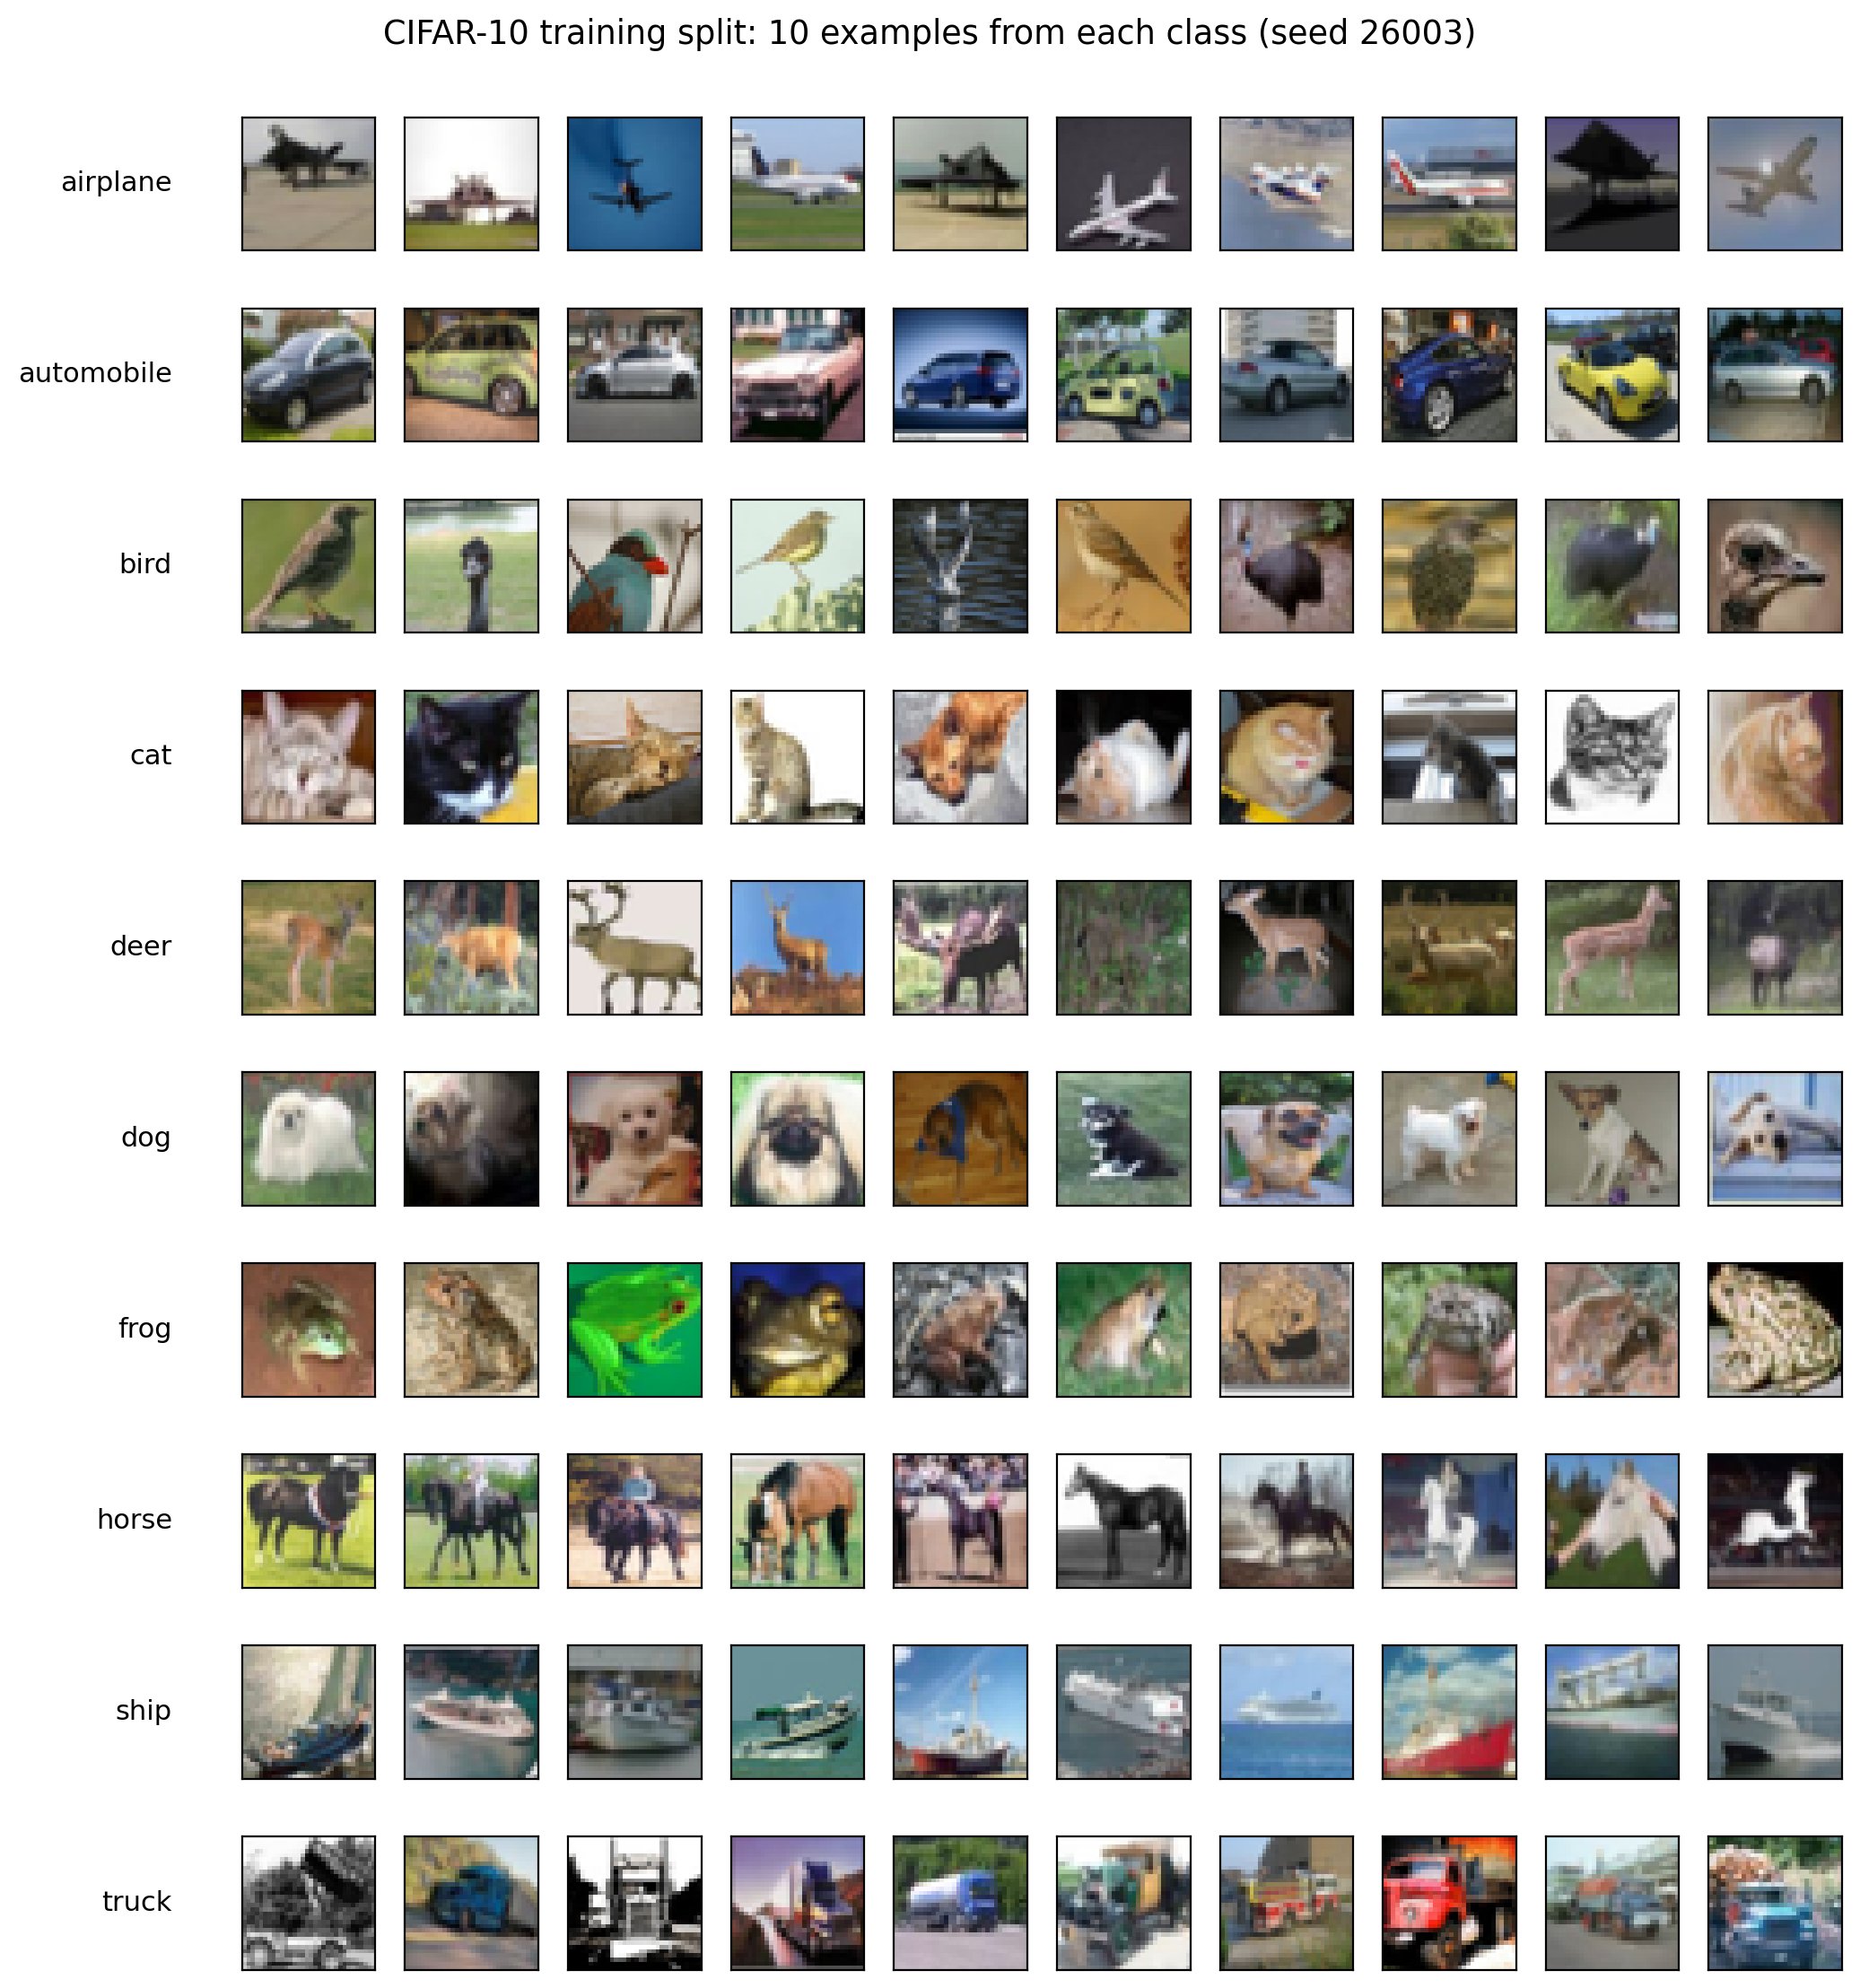

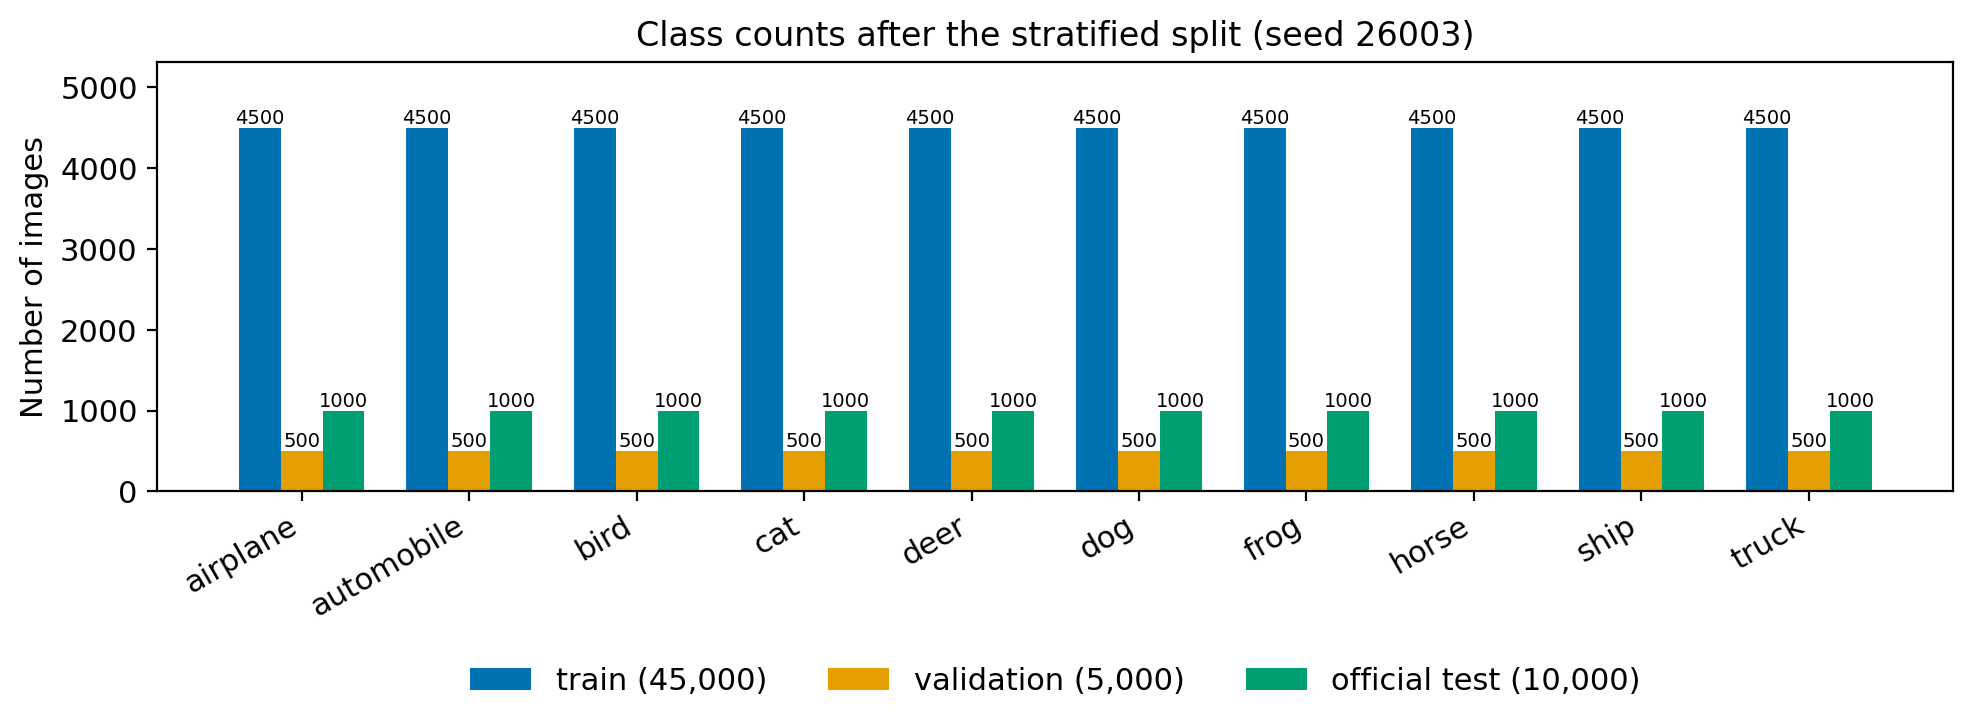

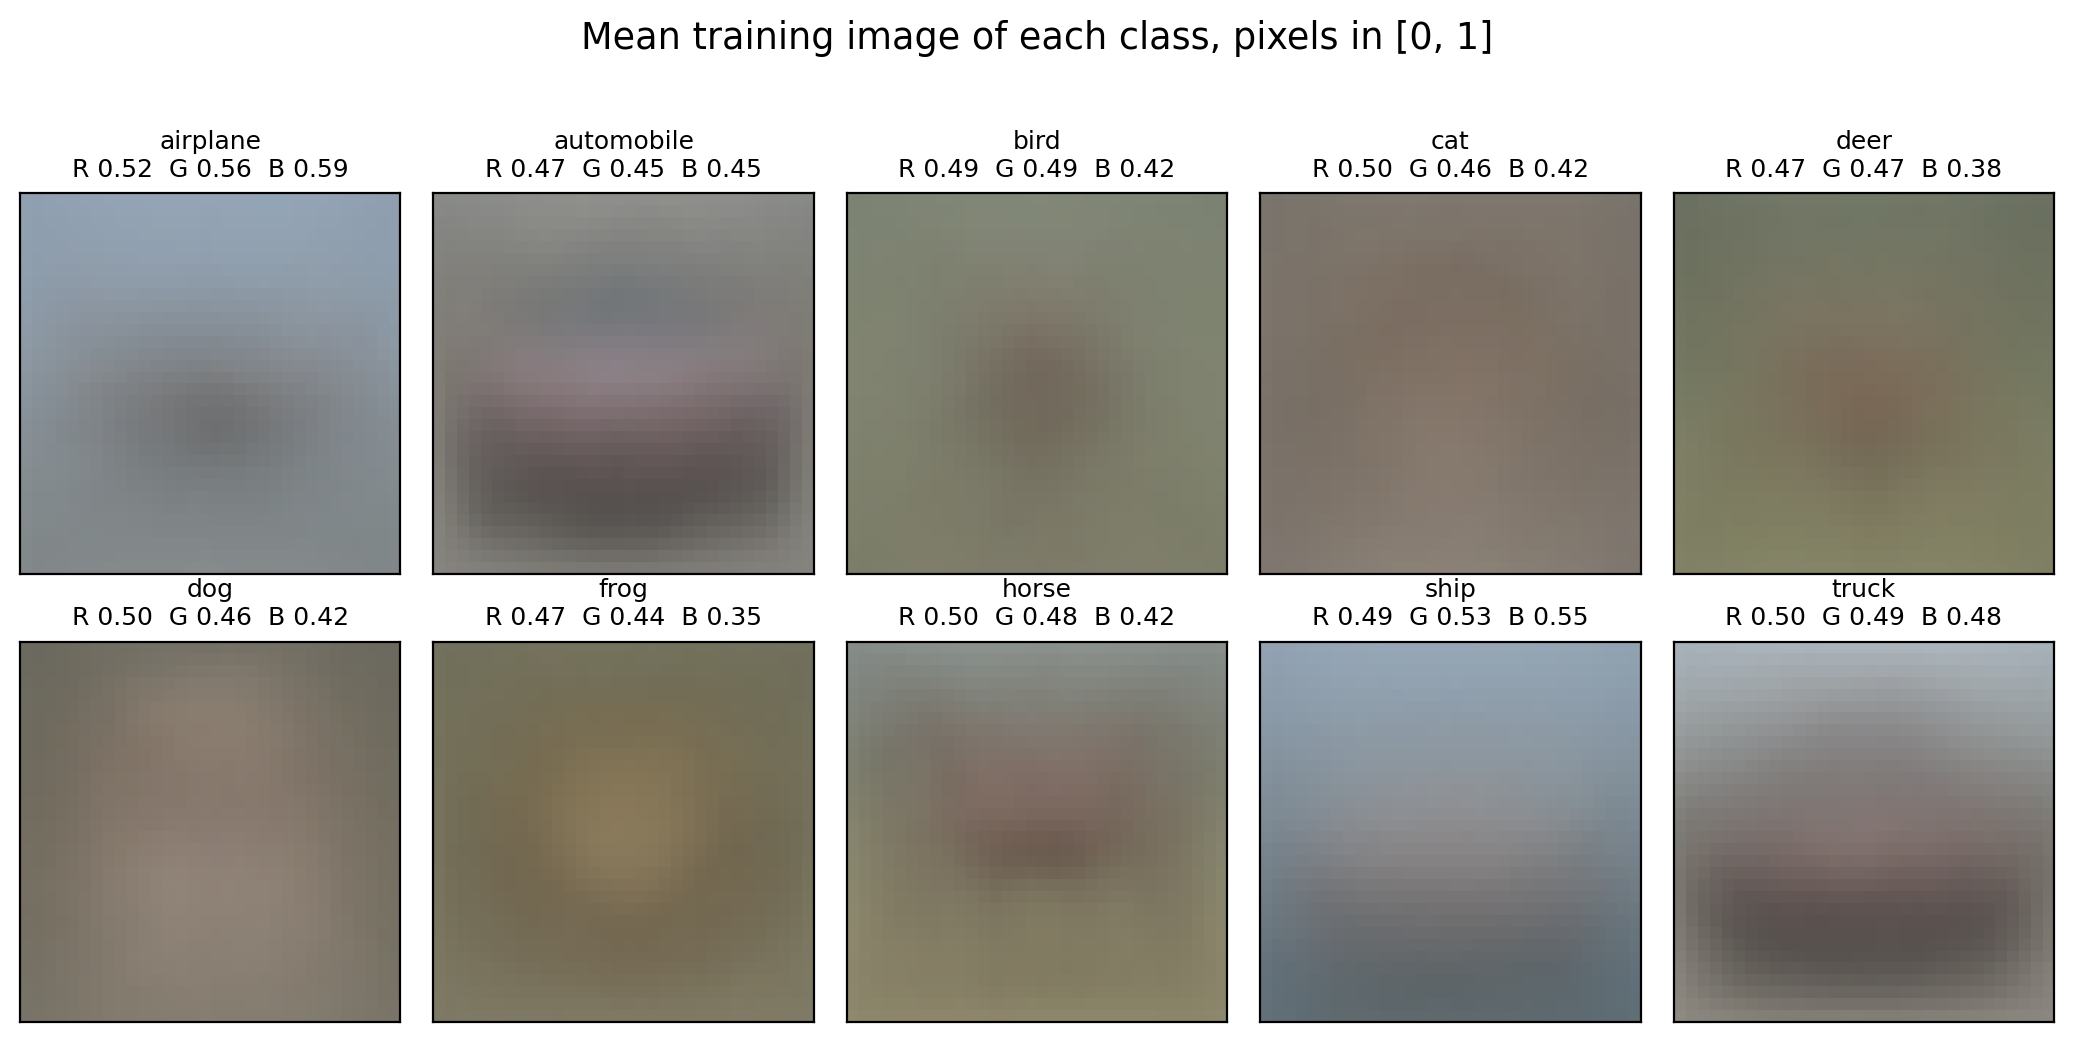

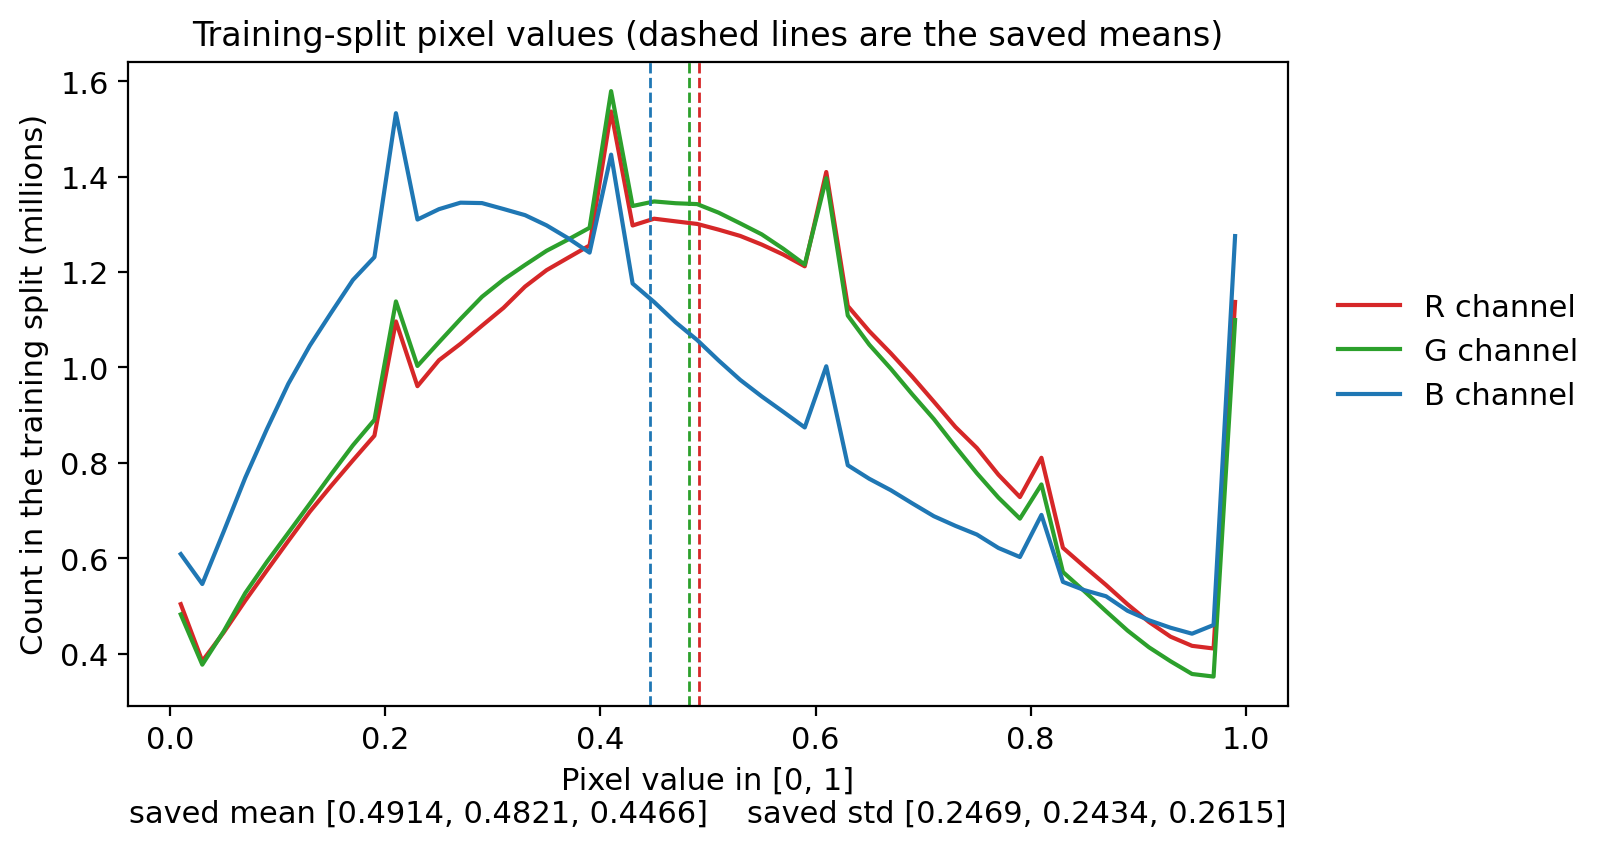

In [2]:
import json
from src.common.data import prepare_dataset, SEED
from src.common.viz import write_dataset_figures

prepared = prepare_dataset(ROOT)
report = prepared["report"]
assert report["train_size"] == 45000
assert report["val_size"] == 5000
assert report["test_size"] == 10000
assert report["overlap"] == 0
assert report["train_counts"] == [4500] * 10
assert int(SEED) == 26003
print("split status:", report["split_status"])
print("train index sha256:", report["train_idx_sha256"])
print("validation index sha256:", report["val_idx_sha256"])
show_rows([{
    "train": report["train_size"],
    "validation": report["val_size"],
    "test": report["test_size"],
    "per class train": report["train_counts"][0],
    "per class validation": report["val_counts"][0],
    "overlap": report["overlap"],
}])
print("train mean RGB:", [round(v, 6) for v in report["mean_rgb"]])
print("train std RGB:", [round(v, 6) for v in report["std_rgb"]])

write_dataset_figures(prepared, ROOT / "figures", ROOT / "results" / "phase1")
for name in ("class_samples.png", "class_distribution.png", "mean_images.png", "pixel_statistics.png"):
    show_figure(f"figures/{name}", width=640)

## 4. Question 1 — design locked before training

The comparison rules are in `configs/q1_fairness.json`. This notebook reads that file. It does not rewrite it. The matched CNN and the matched MLP are within 10% of each other in parameter count. The wide MLP has about 8.5 times as many parameters. The regularised MLP is the same width as the matched MLP, with dropout 0.3 and a stronger weight decay. No model in this comparison is augmented, and none uses batch normalisation.

One learning rate is shared. It was chosen by an 8-epoch validation probe of the matched MLP and the matched CNN. The score is the mean of their best validation accuracies. The wide and regularised models did not get a private search.

In [3]:
import inspect
from src.common.models import MLP, ConvNet, build_model, count_parameters

fairness = json.loads((ROOT / "configs" / "q1_fairness.json").read_text())
print("written before training:", fairness["written_before_training"])
print(fairness["reason_under_test"])
rows = []
for name, spec in fairness["models"].items():
    built = count_parameters(build_model(spec))
    if built != int(spec["parameters"]):
        raise AssertionError(f"{name} has {built} parameters, the plan says {spec['parameters']}.")
    rows.append({
        "model": name,
        "parameters": built,
        "dropout": spec["dropout"],
        "weight_decay": spec["weight_decay"],
    })
show_rows(rows, digits=4)
display(Markdown("### MLP definition used for the logged runs"))
display(Markdown("```python\n" + inspect.getsource(MLP) + "```"))
display(Markdown("### ConvNet definition used for the logged runs"))
display(Markdown("```python\n" + inspect.getsource(ConvNet) + "```"))

written before training: 2026-11-10T13:00:14+05:30
An MLP is weak on CIFAR-10 because it has no spatial weight sharing. Each weight is tied to one pixel position, so a local pattern that moves has to be relearned in every position.


model,parameters,dropout,weight_decay
mlp_matched,201482,0.0000,0.0001
cnn_matched,197194,0.0000,0.0001
mlp_wide,1707274,0.0000,0.0001
mlp_regularised,201482,0.3000,0.0010


### MLP definition used for the logged runs

```python
class MLP(nn.Module):
    """A stack of dense layers on a flattened image.

    Every weight is tied to one pixel position. A pattern that moves a few
    pixels needs a new set of weights, which is the limitation Q1 is about.
    """

    def __init__(self, hidden, dropout=0.0):
        super().__init__()
        layers = []
        in_features = 32 * 32 * 3
        for width in hidden:
            layers.append(nn.Linear(in_features, width))
            layers.append(nn.ReLU())
            # Dropout is off unless this run is the regularised control.
            # It is part of the model rather than the loss so eval() can
            # turn it off when we measure the train/validation gap.
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_features = width
        layers.append(nn.Linear(in_features, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, images):
        flat = images.reshape(images.shape[0], -1)
        return self.net(flat)
```

### ConvNet definition used for the logged runs

```python
class ConvNet(nn.Module):
    """A small convolutional net with global average pooling.

    Each 3x3 filter is reused at every position, which is the inductive
    bias the matched MLP does not have. There is no BatchNorm: that would
    be an extra advantage and would muddy the comparison.
    """

    def __init__(self, widths):
        super().__init__()
        blocks = []
        in_channels = 3
        for width in widths:
            blocks.append(nn.Conv2d(in_channels, width, kernel_size=3, padding=1))
            blocks.append(nn.ReLU())
            # 32 -> 16 -> 8 -> 4 as the three pools run. Locality is kept;
            # the later linear layer never sees a raw pixel.
            blocks.append(nn.MaxPool2d(kernel_size=2))
            in_channels = width
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Linear(in_channels, 10)

    def encode(self, images):
        """Pooled convolutional features, before the linear classifier.

        Q4 freezes this vector. It is the same tensor the Q1 head reads,
        so the representation is not a new network.
        """
        features = self.features(images)
        pooled = self.pool(features)
        return pooled.flatten(1)

    def forward(self, images):
        return self.head(self.encode(images))
```

## 5. Question 1a — logged results

The tables below are read from `results/q1`. Training is not repeated. Final test numbers use the checkpoint with the highest validation accuracy, earliest epoch on a tie, for each of the three seeds 26003, 26004 and 26005. Sample standard deviation uses divisor \(n-1\).

probe rule: mean_best_val_of_matched_mlp_and_cnn_smaller_lr_wins_ties
chosen learning rate: 0.003


learning_rate,mean_best_validation
0.0003,0.5341
0.001,0.6022
0.003,0.6263


Q1 figures written under /scratch/m26csa003/ML_assignment_3/figures/q1


model,parameters,validation,validation_std,test,test_std
Matched MLP,201482,0.5150,0.0031,0.5044,0.0018
Matched CNN,197194,0.7419,0.0314,0.7388,0.0302
Wide MLP,1707274,0.5327,0.0051,0.5267,0.0026
Regularised MLP,201482,0.5137,0.0030,0.5046,0.0039


run,best_epoch,best_validation,train_seconds
cnn_matched_seed26003,27,0.7666,84.9926
cnn_matched_seed26004,27,0.7526,78.5886
cnn_matched_seed26005,25,0.7066,85.5092
mlp_matched_seed26003,10,0.5118,43.4963
mlp_matched_seed26004,21,0.5152,48.5545
mlp_matched_seed26005,20,0.5180,48.7160
mlp_regularised_seed26003,26,0.5164,52.3775
mlp_regularised_seed26004,27,0.5142,49.2225
mlp_regularised_seed26005,30,0.5104,40.0826
mlp_wide_seed26003,30,0.5338,49.2745


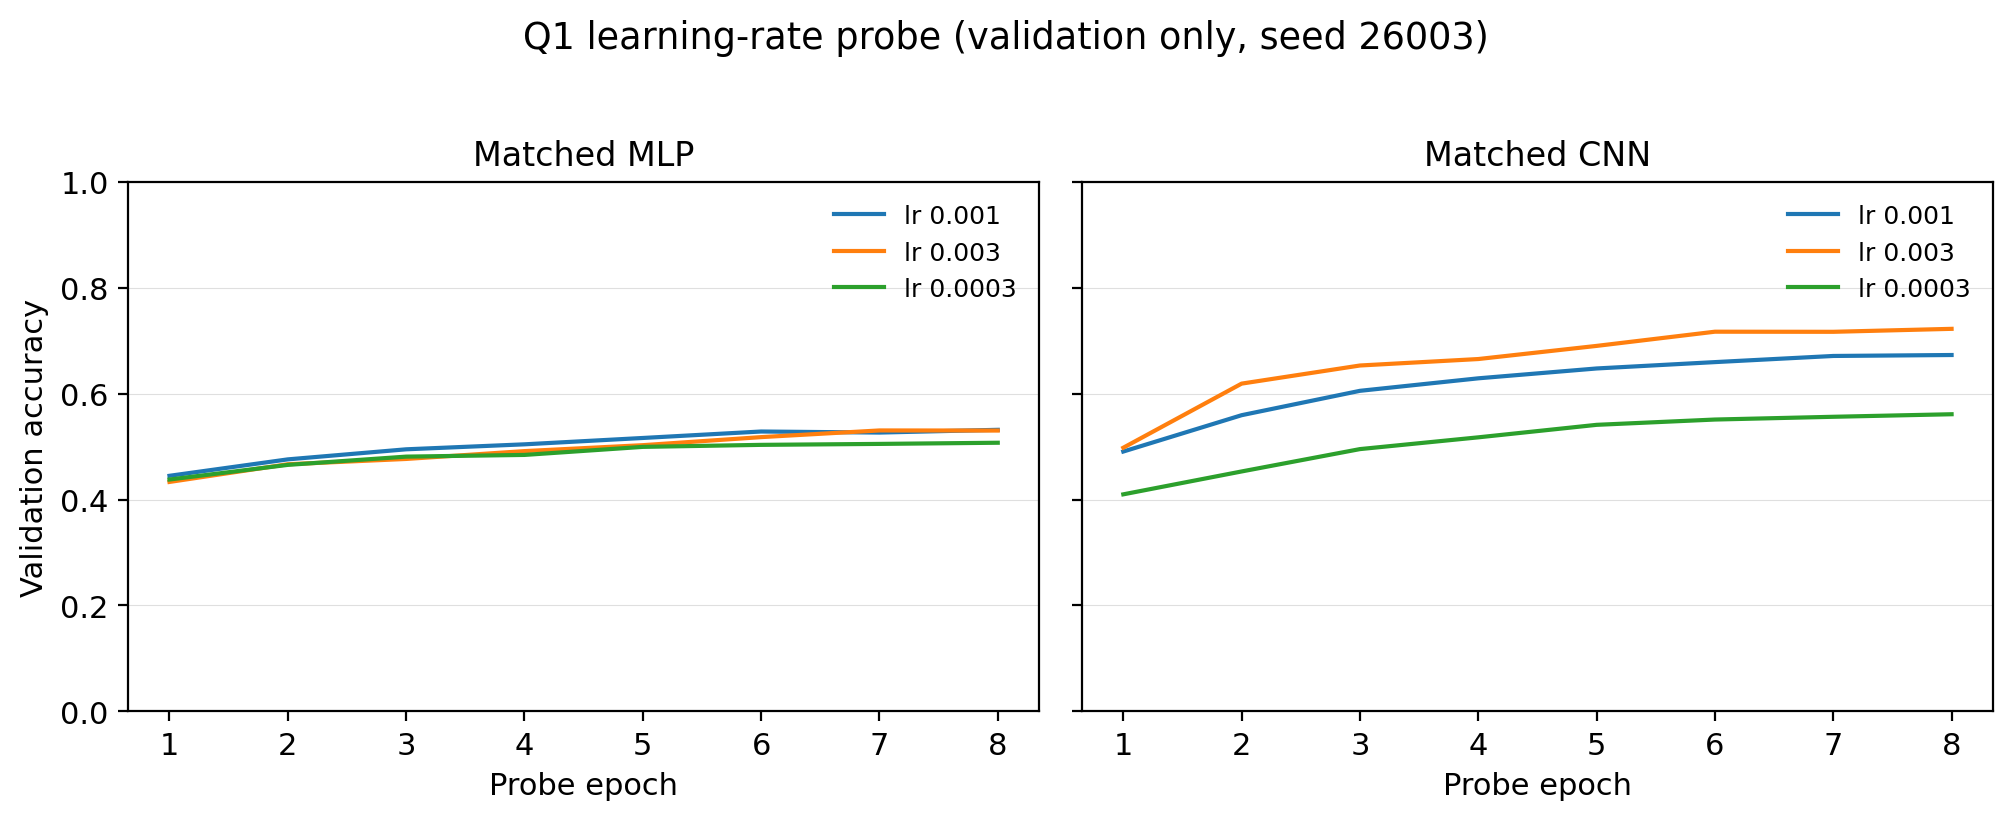

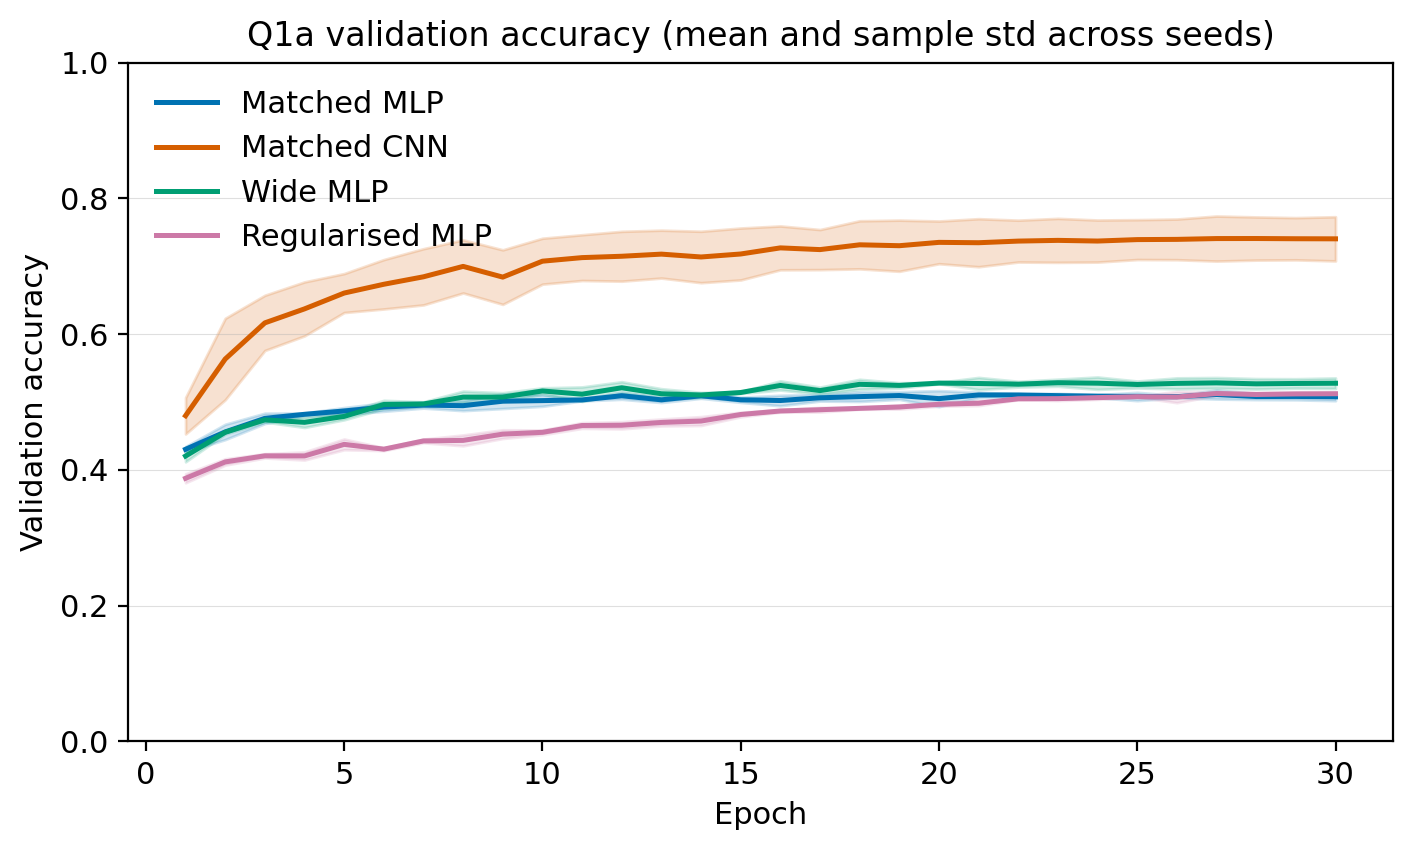

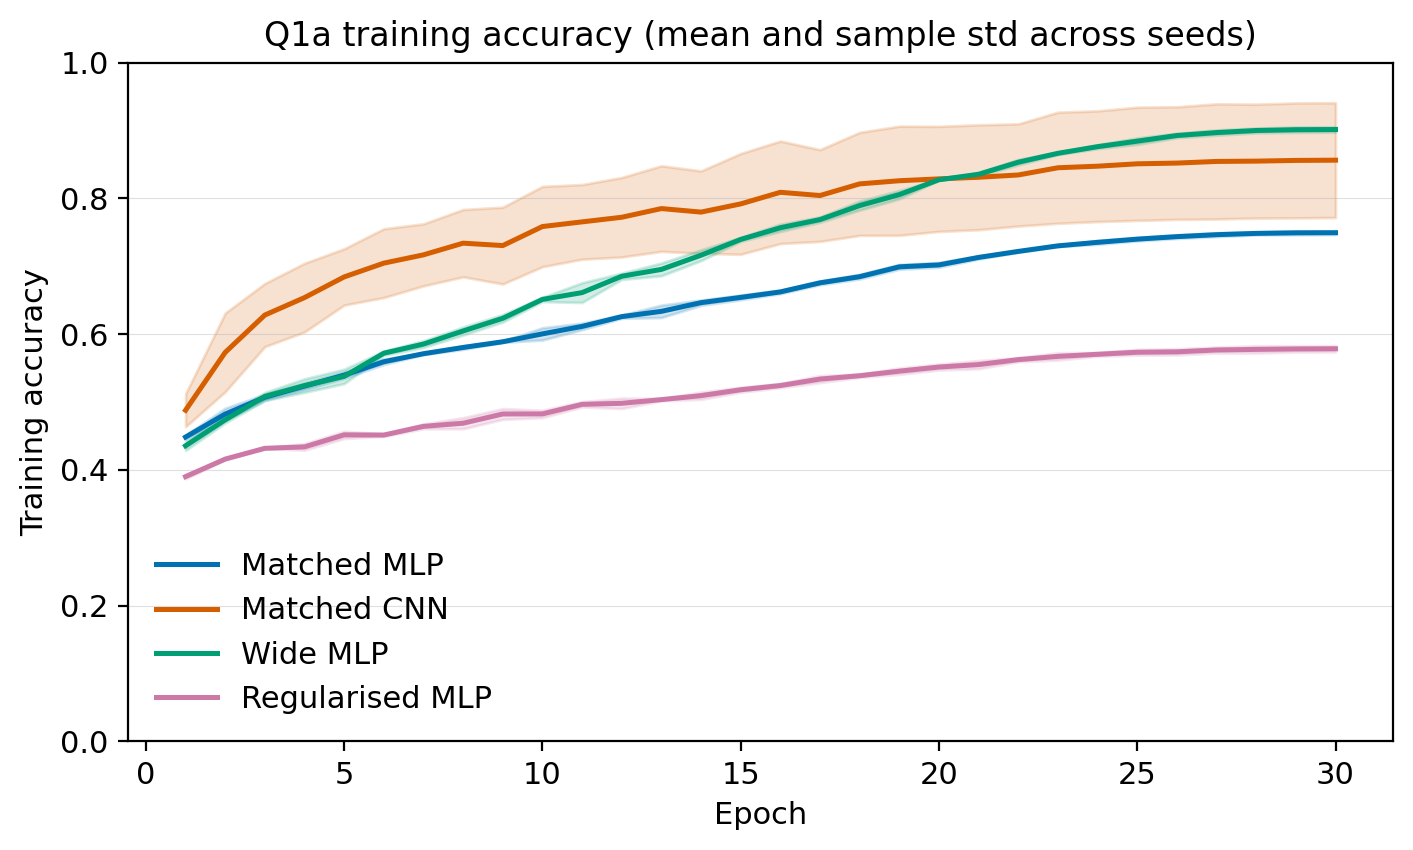

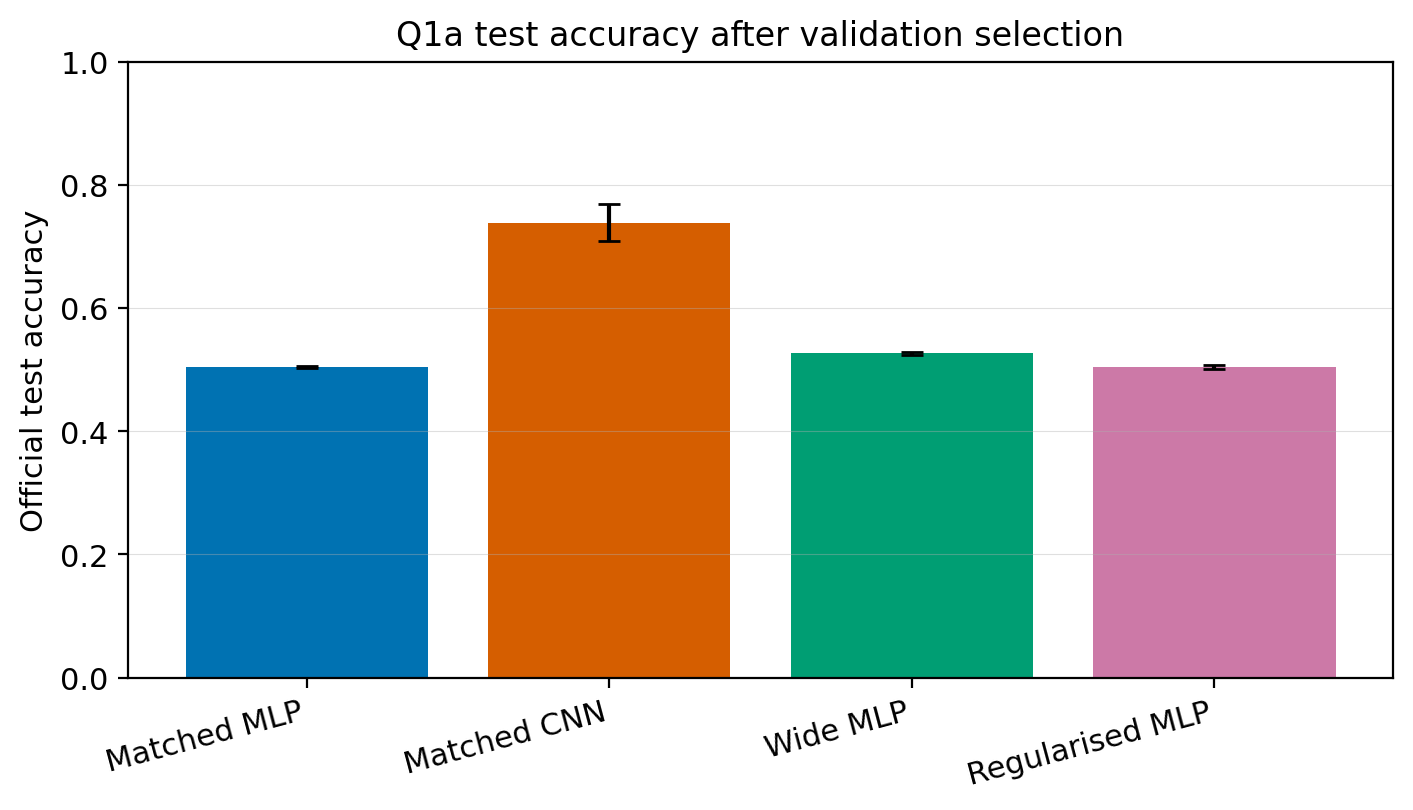

In [4]:
import csv
from src.q1.figures import write_q1_figures

chosen = json.loads((ROOT / "results" / "q1" / "chosen_lr.json").read_text())
print("probe rule:", chosen["rule"])
print("chosen learning rate:", chosen["chosen_lr"])
show_rows([
    {"learning_rate": key, "mean_best_validation": value}
    for key, value in chosen["scores_mean_best_val"].items()
])

write_q1_figures(ROOT)
table_path = ROOT / "results" / "q1" / "q1a_model_table.csv"
with table_path.open() as handle:
    q1_table = list(csv.DictReader(handle))
show_rows([
    {
        "model": row["display_name"],
        "parameters": int(row["parameters"]),
        "validation": float(row["val_accuracy_mean"]),
        "validation_std": float(row["val_accuracy_std"]),
        "test": float(row["test_accuracy_mean"]),
        "test_std": float(row["test_accuracy_std"]),
    }
    for row in q1_table
])

tests = json.loads((ROOT / "results" / "q1" / "test_results.json").read_text())["rows"]
for row in q1_table:
    subset = [item for item in tests if item["model"] == row["model"]]
    mean = sum(item["test_accuracy"] for item in subset) / len(subset)
    if abs(mean - float(row["test_accuracy_mean"])) > 1e-6:
        raise AssertionError(f"{row['model']} table does not match the per-seed test log.")

seconds = []
for path in sorted((ROOT / "results" / "q1" / "final").glob("*.json")):
    payload = json.loads(path.read_text())
    seconds.append({
        "run": path.stem,
        "best_epoch": payload["best_epoch"],
        "best_validation": payload["best_val_accuracy"],
        "train_seconds": payload["seconds"],
    })
show_rows(seconds)
for name in (
    "figures/q1/q1a_lr_probe.png",
    "figures/q1/q1a_val_accuracy.png",
    "figures/q1/q1a_train_accuracy.png",
    "figures/q1/q1a_test_accuracy.png",
):
    show_figure(name)

## 6. Question 1b — structure and memorisation

The wide MLP from Question 1a is trained again with weight decay set to 0, which the fairness file says is not part of the fair comparison. A fixed fraction of training labels is replaced by a wrong class. Validation labels stay clean. Four curves are logged every epoch: accuracy on the untouched training rows, fit to the random labels, accuracy on the true class of the corrupted rows, and clean validation accuracy.

The rule written before training says that useful structure appeared before memorisation only if, at 20% or 50% noise, validation rises while the fit to the random labels is still near chance (10%), and that fit keeps rising after validation has peaked.

fraction,best_epoch,best_val_accuracy,final_clean_accuracy,final_noise_fit,final_true_on_corrupted
0.2,19,0.463400,0.815889,0.394667,0.136889
0.5,6,0.318400,0.564800,0.284756,0.139200
0.0,33,0.533600,0.917956,,
1.0,3,0.100200,,0.102644,0.100000


fraction,epoch,val_accuracy,clean_accuracy,noise_fit,true_on_corrupted,train_accuracy,train_loss
0,1,0.40360000,0.42648889,,,0.42648889,1.62926149
0,33,0.53360000,0.90166667,,,0.90166667,0.26313645
0,40,0.53280000,0.91795556,,,0.91795556,0.22216310
0.2,1,0.39300000,0.39944444,0.07022222,0.38644444,0.33360000,1.94519516
0.2,5,0.45820000,0.51258333,0.08077778,0.43911111,0.42622222,1.75680769
0.2,7,0.45640000,0.54147222,0.09811111,0.42222222,0.45280000,1.66267646
0.2,19,0.46340000,0.70230556,0.22822222,0.30133333,0.60748889,1.15201831
0.2,40,0.43920000,0.81588889,0.39466667,0.13688889,0.73164444,0.68775368
0.5,1,0.29480000,0.29137778,0.08333333,0.28640000,0.18735556,2.22848172
0.5,6,0.31840000,0.36106667,0.09017778,0.30826667,0.22562222,2.15697671


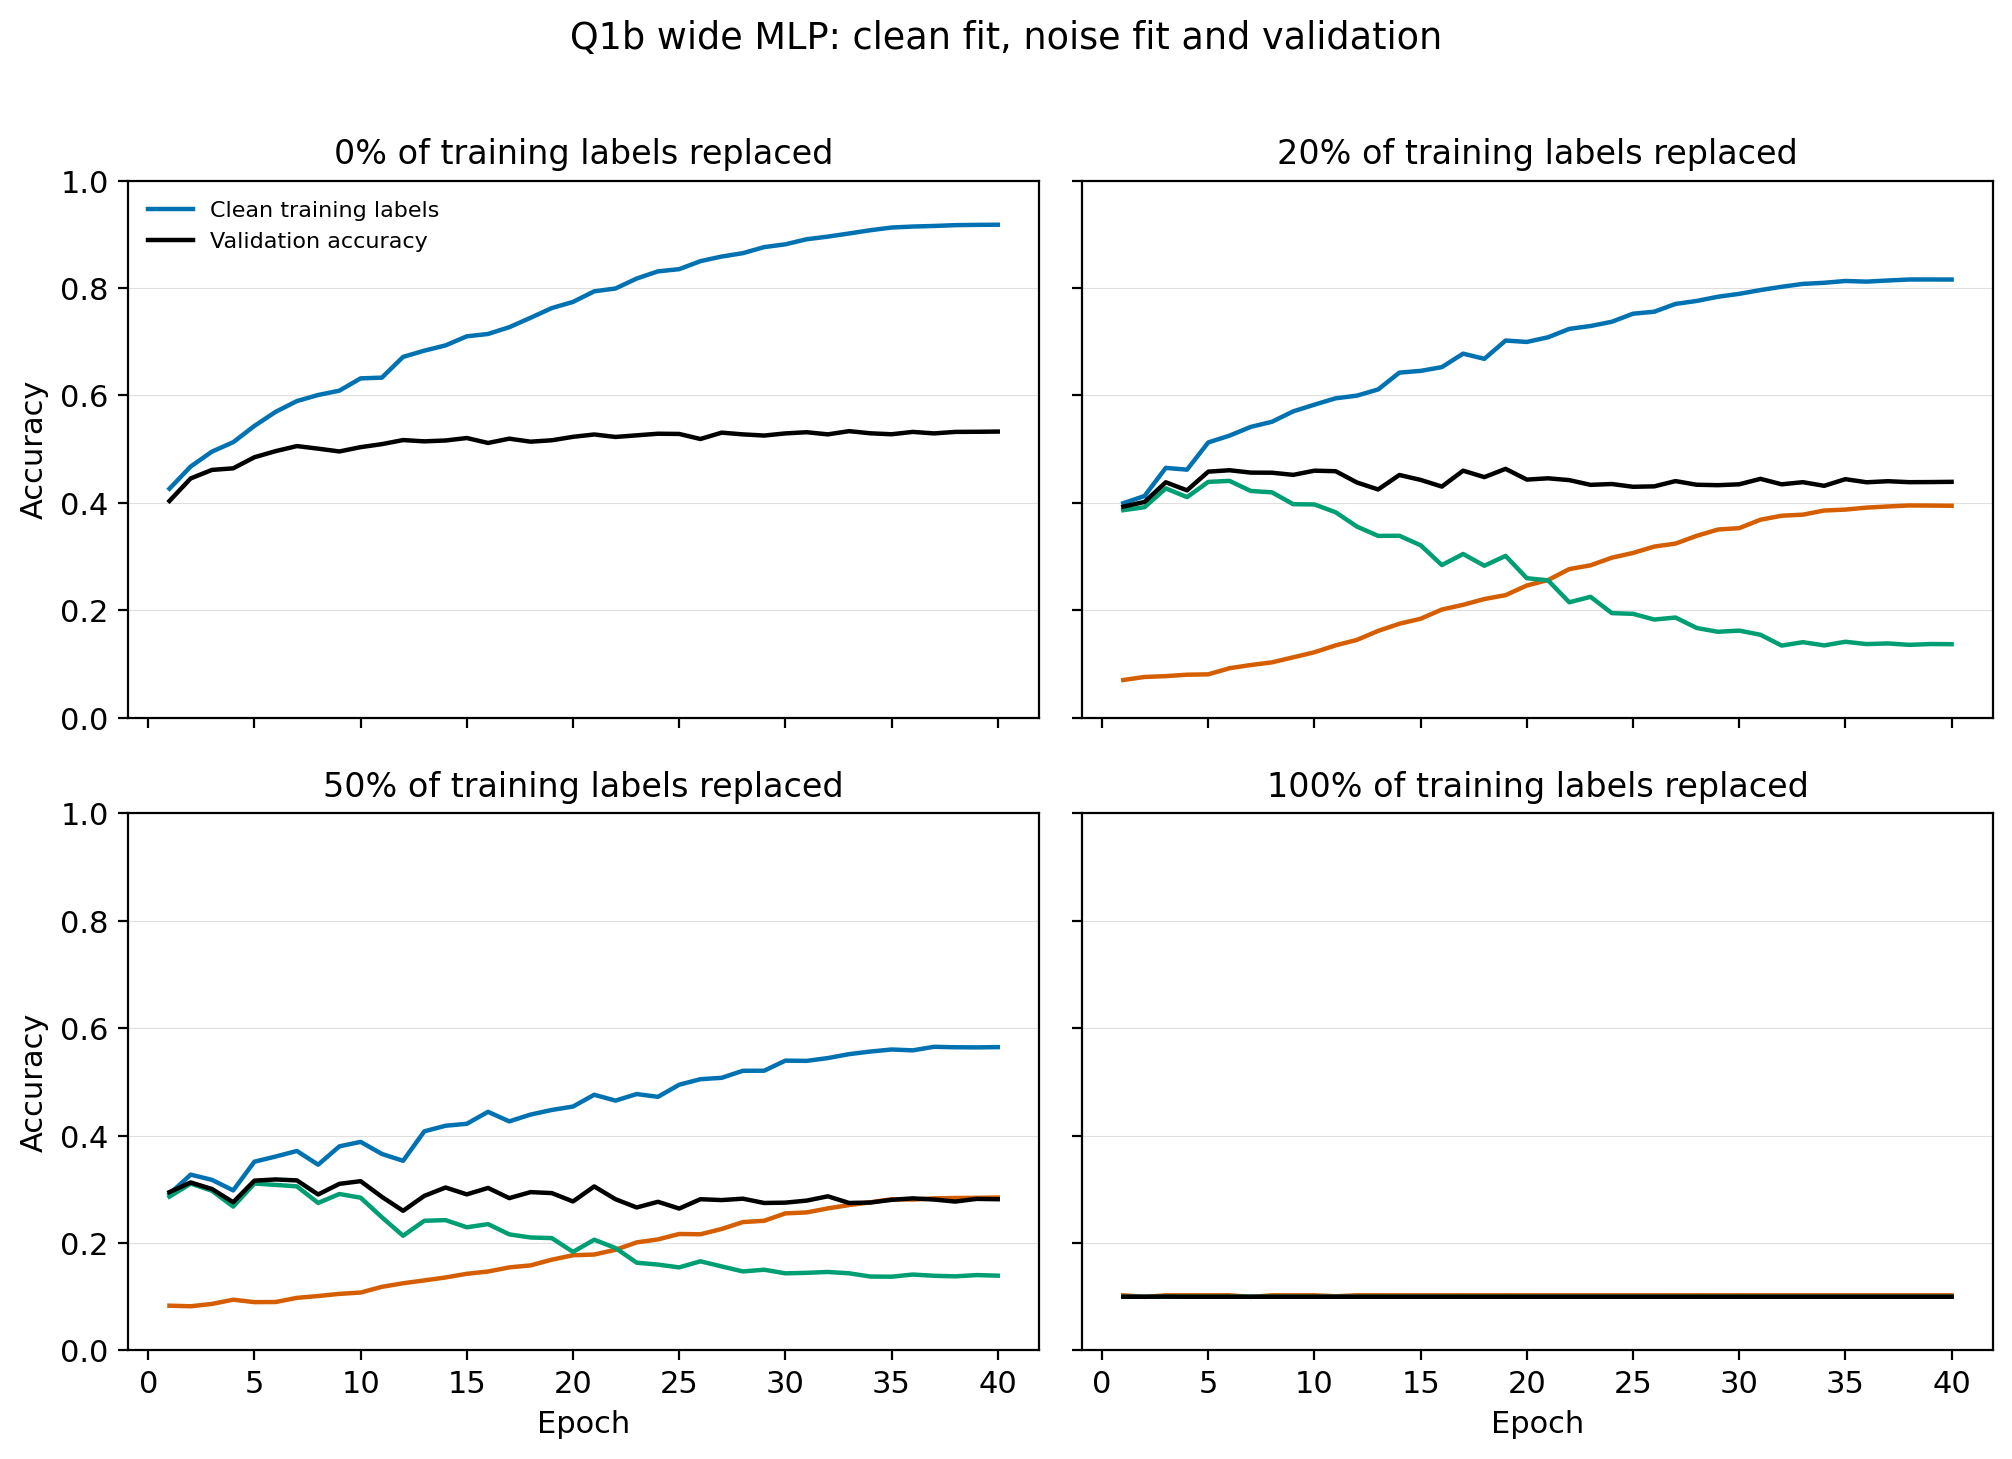

In [5]:
with (ROOT / "results" / "q1" / "q1b_summary.csv").open() as handle:
    memo = list(csv.DictReader(handle))
show_rows(memo, digits=4)
with (ROOT / "results" / "q1" / "q1b_milestones.csv").open() as handle:
    milestones = list(csv.DictReader(handle))
show_rows(milestones, digits=4)
show_figure("figures/q1/q1b_memorisation.png", width=780)

### Reading of Question 1

The matched CNN's test accuracy is 0.739 ± 0.030. The matched MLP is 0.504 ± 0.002. About 8.5 times as many parameters move the MLP test accuracy to 0.527 ± 0.003. Dropout and a stronger weight decay leave it at 0.505 ± 0.004. The extra parameters overfit: training accuracy goes high and the test loss stays high. The gap that remains is the one the plan attributed to missing spatial weight sharing.

At 20% label noise, validation rises from 0.393 to 0.458 in five epochs while the random-label fit stays at 0.070–0.081. It peaks at 0.463 on epoch 19, and the random-label fit then continues from 0.228 to 0.395. At 50% noise the validation peak is 0.318 on epoch 6, while the noise fit is still 0.090, and the noise fit later reaches 0.285 as validation falls to 0.282. That is the pre-written condition, with a small useful gain at 50%. At 100% noise the training loss stays at \(\ln 10\) and nothing leaves chance, so this budget did not fit a fully random training set.

## 7. Question 2 — permutation and grayscale

Part (a) does not train a new pair. It reuses the matched models from Question 1a. Parts (b) and (c) retrain both models with the same optimiser, the same learning rate 0.003, 30 epochs, and the three seeds. A single permutation of the 1,024 spatial positions is saved and applied to every image and every channel. Grayscale uses luma \(0.2989 R + 0.5870 G + 0.1140 B\), repeated on three channels so the parameter counts do not change. Mean and standard deviation for the grayscale images are computed on the training split only.

written before the retraining: 2026-11-10T17:48:52+05:30
Part (b) expectation:
A fixed spatial permutation does not change the functions an MLP can represent, so the matched MLP's test accuracy should stay within about 3 points of its clean 50.4%. The matched CNN should drop by well more than 10 points, toward the MLP, because a 3x3 filter no longer sits on a real neighbourhood. If the CNN stays within 5 points of its clean 73.9%, the spatial explanation from part (a) is not supported.

Part (c) expectation:
The two explanations are: the CNN uses local shape through weight sharing, or the CNN uses colour. Grayscale keeps spatial structure and removes colour. If shape is the reason, the grayscale CNN should stay more than 10 points above the grayscale MLP and should remain clearly above 60%. If colour is the reason, the CNN should fall close to the MLP. Confidence is measured rather than predicted: the report will compare correct and incorrect confidence and will not claim calibration b

model,condition,parameters,test,test_std,confidence_correct,confidence_wrong,high_conf_error_fraction
mlp_matched,clean,201482,0.5044,0.0018,0.7236,0.5405,0.0777
mlp_matched,permuted,201482,0.5011,0.0029,0.7249,0.5392,0.0709
mlp_matched,grayscale,201482,0.4186,0.0049,0.6115,0.4521,0.0325
cnn_matched,clean,197194,0.7388,0.0302,0.8621,0.6482,0.1482
cnn_matched,permuted,197194,0.4856,0.0285,0.5989,0.4400,0.0085
cnn_matched,grayscale,197194,0.6120,0.1224,0.7168,0.5148,0.0558


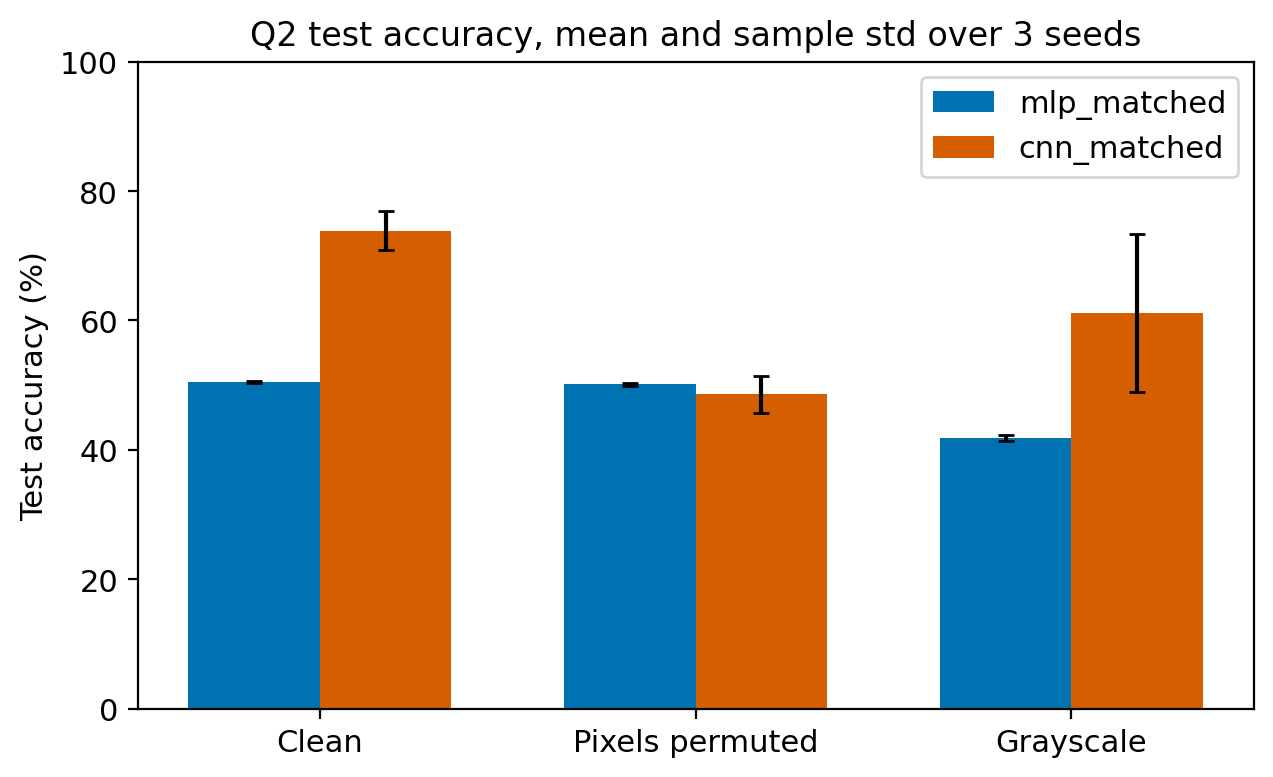

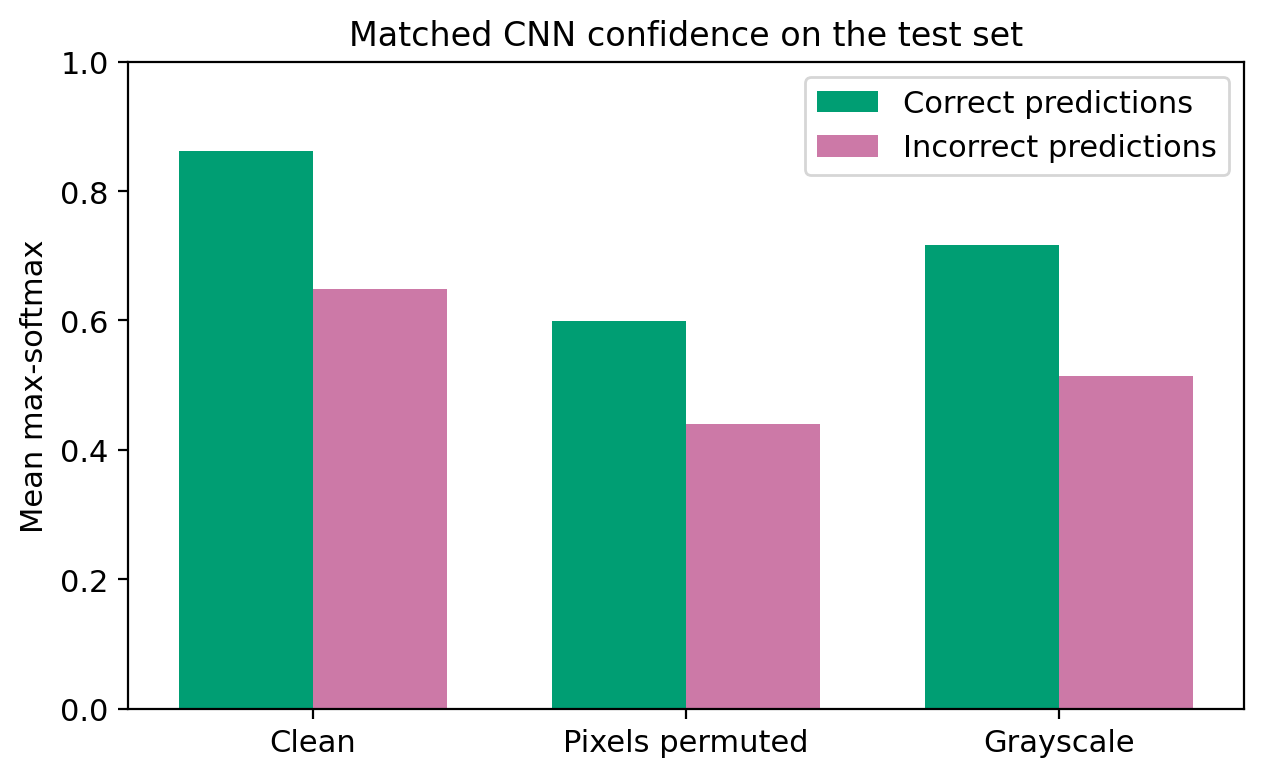

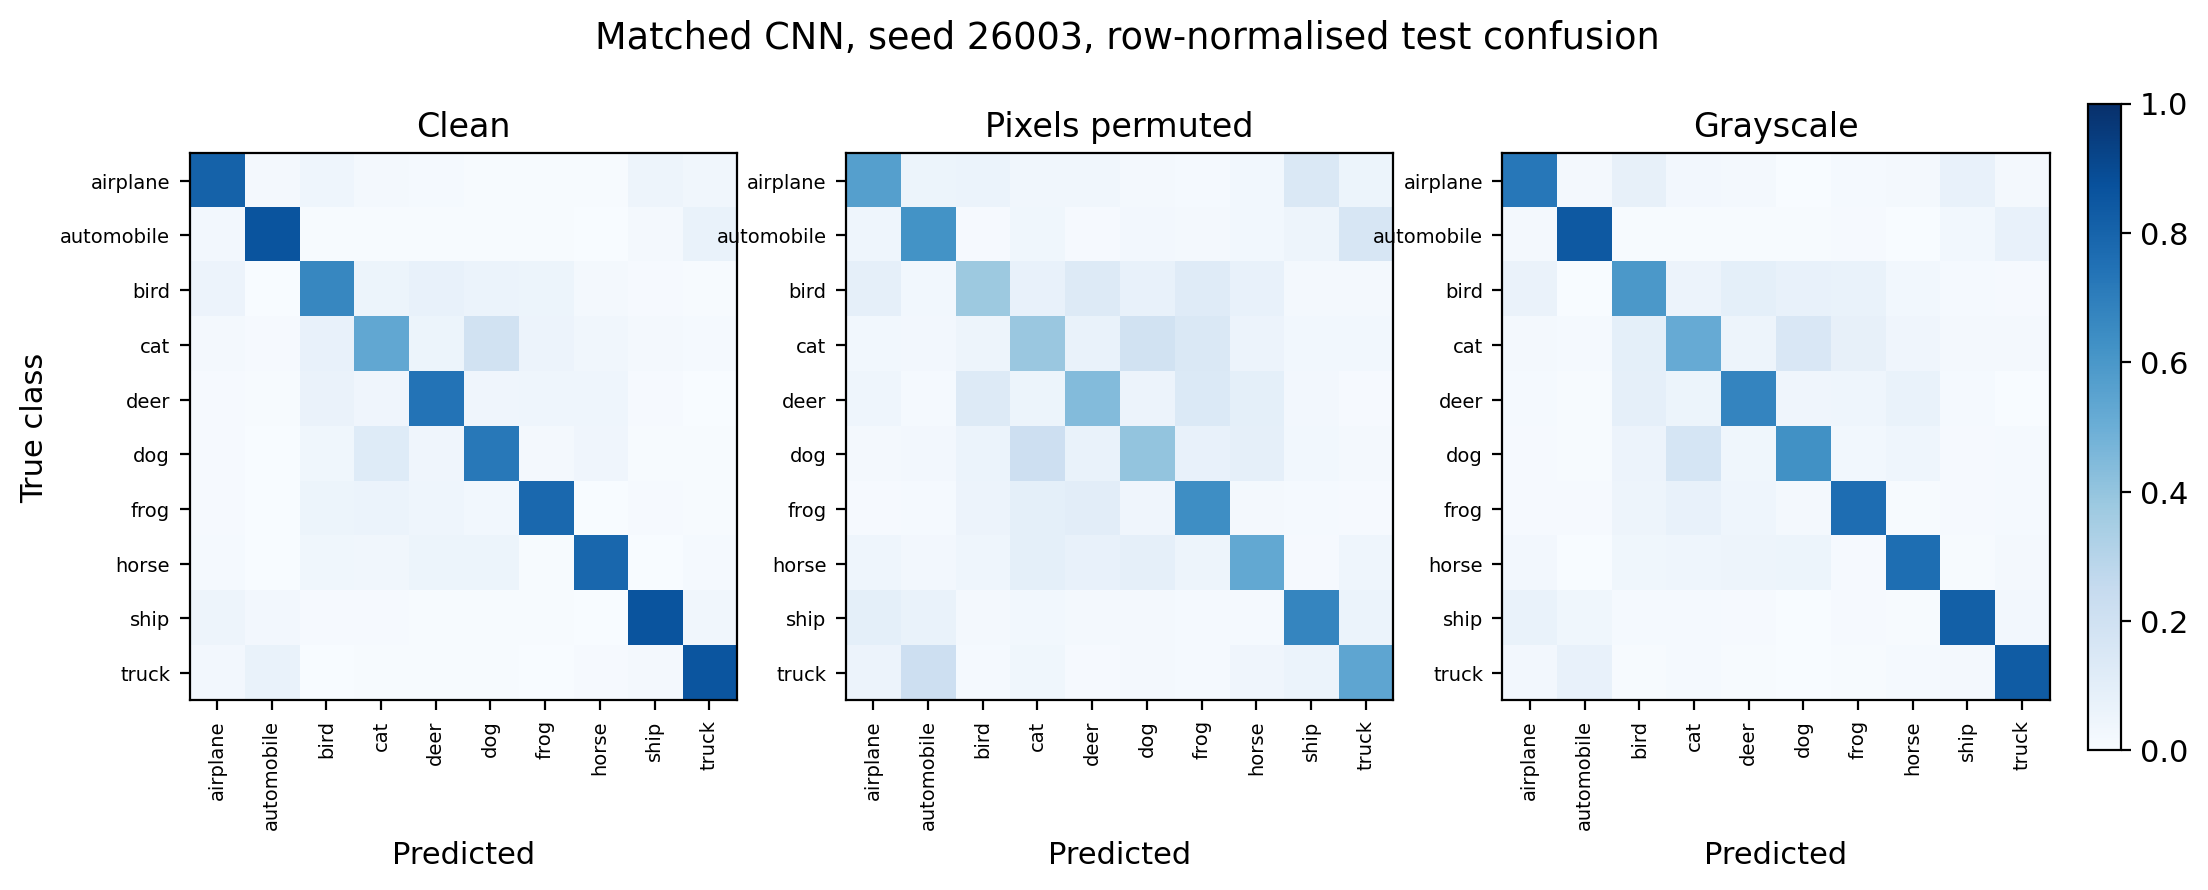

In [6]:
from src.q2.figures import write_q2_figures

plan = json.loads((ROOT / "configs" / "q2_plan.json").read_text())
print("written before the retraining:", plan["written_before_training"])
print("Part (b) expectation:")
print(plan["expectations_before_training"]["part_b"])
print()
print("Part (c) expectation:")
print(plan["expectations_before_training"]["part_c"])
write_q2_figures(ROOT)
with (ROOT / "results" / "q2" / "q2_summary.csv").open() as handle:
    q2_rows = list(csv.DictReader(handle))
show_rows([
    {
        "model": row["model"],
        "condition": row["condition"],
        "parameters": int(float(row["parameters"])),
        "test": float(row["test_accuracy_mean"]),
        "test_std": float(row["test_accuracy_std"]),
        "confidence_correct": float(row["confidence_correct_mean"]),
        "confidence_wrong": float(row["confidence_incorrect_mean"]),
        "high_conf_error_fraction": float(row["high_confidence_error_fraction_mean"]),
    }
    for row in q2_rows
])
# The clean re-evaluation has to match the Question 1 test log.
q1_cnn = next(row for row in q1_table if row["model"] == "cnn_matched")
q2_cnn = next(row for row in q2_rows if row["model"] == "cnn_matched" and row["condition"] == "clean")
if abs(float(q1_cnn["test_accuracy_mean"]) - float(q2_cnn["test_accuracy_mean"])) > 1e-4:
    raise AssertionError("Clean CNN test accuracy disagrees between Question 1 and Question 2.")
for name in (
    "figures/q2/q2_test_accuracy.png",
    "figures/q2/q2_confidence.png",
    "figures/q2/q2_confusion_cnn_seed26003.png",
):
    show_figure(name, width=760)

### Reading of Question 2

After the pixel permutation the MLP test accuracy is 0.501 ± 0.003, inside the band expected around its clean 0.504. The CNN falls from 0.739 to 0.486 ± 0.028. The spatial explanation holds: once a 3×3 filter no longer sits on a neighbourhood, the CNN loses the advantage.

On grayscale the MLP is 0.419 ± 0.005 and the CNN mean is 0.612 ± 0.122. The three CNN seeds are 0.715, 0.645 and 0.476. Two seeds stay well above the MLP and above 0.60. Seed 26005 has validation accuracy 0.490, so the "above 60%" sentence is not true of every seed. Colour is used by both models. It does not, on the two stable seeds, explain the clean-image gap.

Correct predictions have a higher mean max-softmax than incorrect ones in every condition. After the permutation, the fraction of CNN errors with confidence at least 0.9 falls from 0.148 to 0.008.

## 8. Summary of Part 1

The matched CNN leads the matched MLP by about 23 test points under a matched parameter budget, a shared learning rate, and no augmentation. A much wider MLP and a regularised MLP do not close that gap. A fixed spatial permutation removes the CNN's lead and leaves the MLP essentially unchanged. Removing colour lowers both models; the CNN lead survives in two of three seeds and fails in the third.

Question 3 and Question 4 are in `Assignment_3_Part_2.ipynb`. That notebook reads these logs from disk. It does not need this kernel.

In [7]:
if RECOMPUTE:
    from src.q1.pipeline import main as train_q1
    from src.q2.pipeline import main as train_q2
    train_q1()
    train_q2()
else:
    print("Using the saved Question 1 and Question 2 logs. Retraining is scripts/q1_srun.sh and the Q2 section of scripts/q234_srun.sh.")

Using the saved Question 1 and Question 2 logs. Retraining is scripts/q1_srun.sh and the Q2 section of scripts/q234_srun.sh.
